# MetaIntegrator R: SLE Meta-Analysis

**Based on the official MetaIntegrator Real Example vignette**

This notebook demonstrates the complete meta-analysis workflow for Systemic Lupus Erythematosus (SLE) using three public GEO datasets: GSE11909, GSE50635, GSE39088.

---

## 1. Setup

In [1]:
library(MetaIntegrator)
set.seed(42)
options(repr.plot.width = 10, repr.plot.height = 7)

# Whether to save raw plot data to CSV for cross-platform plotting
SAVE_PLOT_DATA <- TRUE
PLOT_DATA_DIR <- "output_sle_tutorial_r_analysis/plot_data"
dir.create(PLOT_DATA_DIR, recursive = TRUE, showWarnings = FALSE)

save_plot_data <- function(data, filename, description = "") {
    if (SAVE_PLOT_DATA) {
        filepath <- file.path(PLOT_DATA_DIR, filename)
        write.csv(data, filepath, row.names = TRUE)
        cat(sprintf("  Plot data saved: %s\n", filepath))
    }
}

cat(sprintf("R version: %s\n", R.version.string))
cat(sprintf("MetaIntegrator version: %s\n", as.character(packageVersion("MetaIntegrator"))))
cat("Setup complete.\n")

R version: R version 4.5.2 (2025-10-31)
MetaIntegrator version: 2.1.3
Setup complete.


## 2. Get Public Gene Expression Data

Download three SLE datasets from GEO. First run takes ~5-10 minutes.

In [2]:
sleData <- getGEOData(c("GSE11909", "GSE50635", "GSE39088"))
cat(sprintf("\nDownloaded datasets: %s\n", paste(names(sleData$originalData), collapse=", ")))

Setting options('download.file.method.GEOquery'='auto')

Setting options('GEOquery.inmemory.gpl'=FALSE)

Found 2 file(s)

GSE11909-GPL96_series_matrix.txt.gz

GSE11909-GPL97_series_matrix.txt.gz

Found 1 file(s)

GSE50635_series_matrix.txt.gz

Found 1 file(s)

GSE39088_series_matrix.txt.gz



         Length Class  Mode
GSE11909 2      -none- list
GSE50635 1      -none- list
GSE39088 1      -none- list
[1] "GSE11909-GPL96_series_matrix.txt.gz" "GSE11909-GPL97_series_matrix.txt.gz"
[1] "GSE11909-GPL96_series_matrix.txt.gz" "GSE11909-GPL97_series_matrix.txt.gz"
[1] "GSE50635_series_matrix.txt.gz"
[1] "GSE39088_series_matrix.txt.gz"

Downloaded datasets: GSE11909_GPL96, GSE11909_GPL97, GSE50635, GSE39088


### Inspect Downloaded Data

In [3]:
for(name in names(sleData$originalData)) {
    n <- ncol(sleData$originalData[[name]]$expr)
    g <- nrow(sleData$originalData[[name]]$expr)
    cat(sprintf("  %s: %d samples, %d genes\n", name, n, g))
}

  GSE11909_GPL96: 115 samples, 22283 genes
  GSE11909_GPL97: 60 samples, 22645 genes
  GSE50635: 49 samples, 33297 genes
  GSE39088: 142 samples, 54675 genes


## 3. Label Samples

Assign class labels: 1 = SLE (disease), 0 = healthy (control).

In [4]:
sleData$originalData$GSE50635 <- classFunction(
    sleData$originalData$GSE50635,
    column = "subject type:ch1",
    diseaseTerms = c("Subject RBP +", "Subject RBP -")
)

sleData$originalData$GSE11909_GPL96 <- classFunction(
    sleData$originalData$GSE11909_GPL96,
    column = "Illness:ch1",
    diseaseTerms = c("SLE")
)

sleData$originalData$GSE39088 <- classFunction(
    sleData$originalData$GSE39088,
    column = "disease state:ch1",
    diseaseTerms = c("SLE")
)

sleData$originalData$GSE11909_GPL97 <- classFunction(
    sleData$originalData$GSE11909_GPL97,
    column = "Illness:ch1",
    diseaseTerms = c("SLE")
)

# Verify labels
for(name in names(sleData$originalData)) {
    cls <- sleData$originalData[[name]]$class
    nd <- sum(cls == 1)
    nc <- sum(cls == 0)
    cat(sprintf("  %s: %d disease, %d control\n", name, nd, nc))
}
cat("Labeling complete.\n")

  GSE11909_GPL96: 103 disease, 12 control
  GSE11909_GPL97: 53 disease, 7 control
  GSE50635: 33 disease, 16 control
  GSE39088: 78 disease, 64 control
Labeling complete.


## 4. Run Meta-Analysis

Found common probes in 2 
Found common probes in 4 
Computing effect sizes...
Computing summary effect sizes...
Computing Fisher's output...

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the MetaIntegrator package.
  Please report the issue to the authors.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the MetaIntegrator package.
  Please report the issue to the authors.”


Found common probes in 3 
Computing effect sizes...
Computing summary effect sizes...
Computing Fisher's output...Found common probes in 3 
Computing effect sizes...
Computing summary effect sizes...
Computing Fisher's output...Found common probes in 2 
Found common probes in 3 
Computing effect sizes...
Computing summary effect sizes...
Computing Fisher's output...Found common probes in 2 
Computing effect sizes...
Computing summary effect sizes...
Computing Fisher's output...Genes analyzed: 25822
Significant (FDR < 0.05): 2559


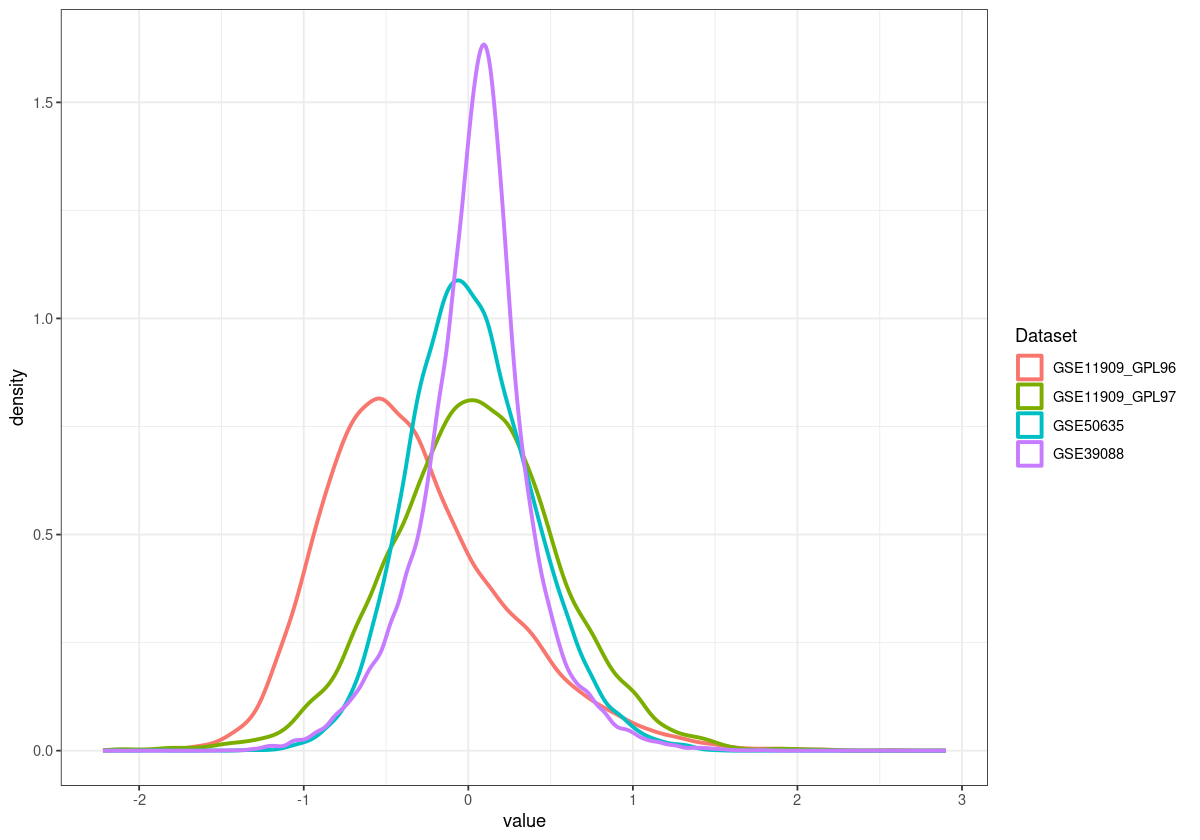

In [5]:
sleMetaAnalysis <- runMetaAnalysis(sleData, runLeaveOneOutAnalysis = TRUE, maxCores = 1)

# Inspect
n_total <- nrow(sleMetaAnalysis$metaAnalysis$pooledResults)
n_sig <- sum(sleMetaAnalysis$metaAnalysis$pooledResults$effectSizeFDR < 0.05, na.rm = TRUE)
cat(sprintf("Genes analyzed: %d\nSignificant (FDR < 0.05): %d\n", n_total, n_sig))

## 5. Filter Genes

In [6]:
sleMetaAnalysis <- filterGenes(sleMetaAnalysis, isLeaveOneOut = TRUE, effectSizeThresh = 1, FDRThresh = 0.05)

filterResults <- sleMetaAnalysis$filterResults[[1]]
cat(sprintf("Up-regulated: %d genes\n", length(filterResults$posGeneNames)))
cat(sprintf("Down-regulated: %d genes\n", length(filterResults$negGeneNames)))
cat(sprintf("Top 5 up: %s\n", paste(head(filterResults$posGeneNames, 5), collapse=", ")))
cat(sprintf("Top 5 down: %s\n", paste(head(filterResults$negGeneNames, 5), collapse=", ")))

Up-regulated: 13 genes
Down-regulated: 3 genes
Top 5 up: MT1F, FCGR1B, IFITM1, IFI27, SCNM1
Top 5 down: DDX6, ABCB1, MID2


## 6. Calculate Meta Score

In [7]:
sleScores <- calculateScore(
    filterObject = sleMetaAnalysis$filterResults[[1]],
    datasetObject = sleMetaAnalysis$originalData[[1]]
)
cat(sprintf("MetaScore range: [%.3f, %.3f]\n", min(sleScores), max(sleScores)))

Used  13 of  13  pos genes, and  3  of  3  neg genes 
MetaScore range: [-2.157, 1.931]


## 7. Visualizations

### 7.1 Heatmap

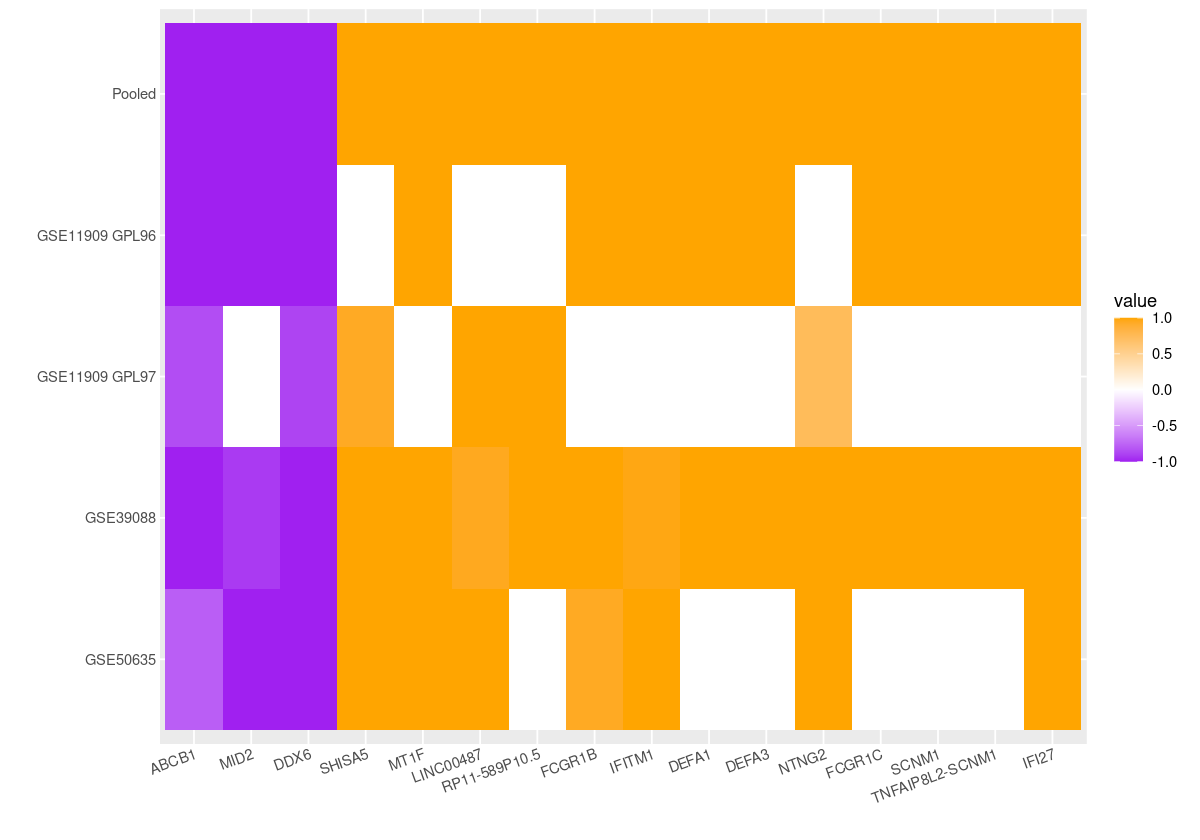

In [8]:
heatmapPlot(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]])

### 7.2 Multiple ROC Curves

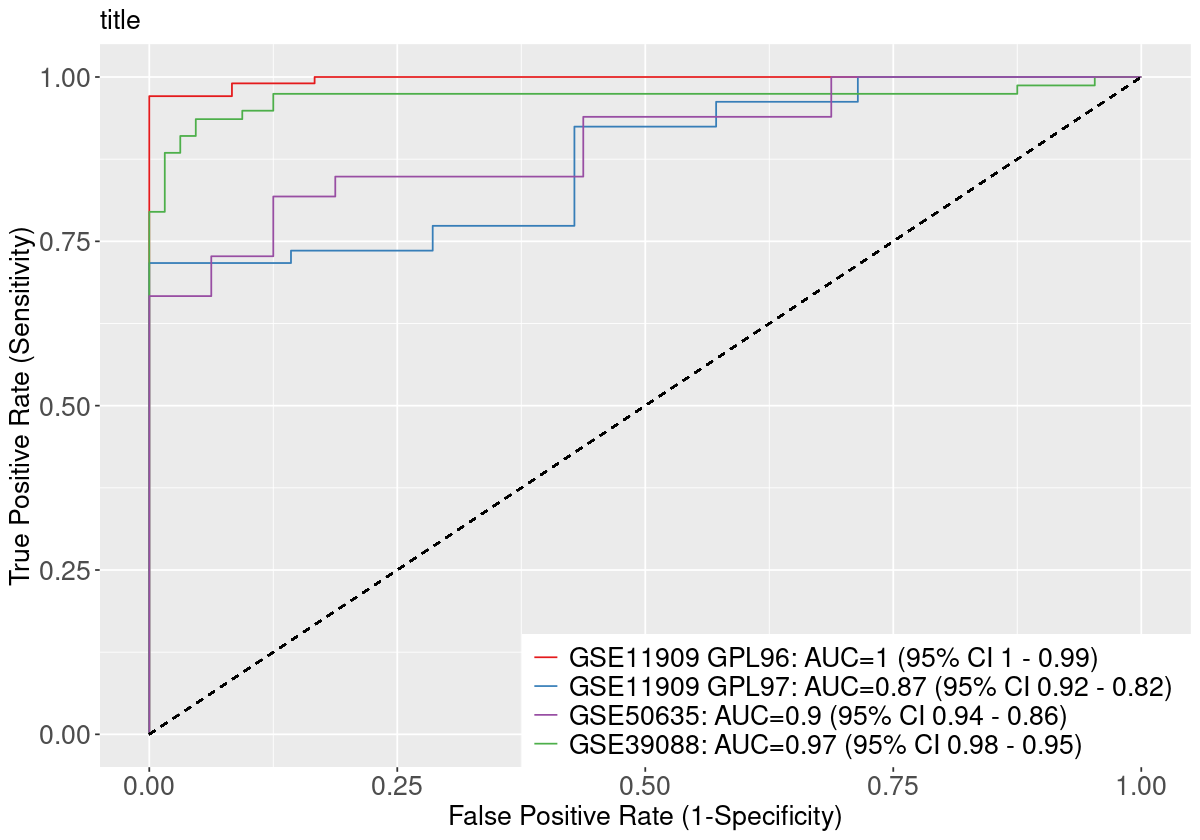

In [9]:
multipleROCPlot(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]])

### 7.3 Summary ROC


 GSE11909 GPL96 	treated as AUC=1
 GSE11909 GPL97 		Bootstrapping...	
 GSE50635 		Bootstrapping...	
 GSE39088 		Bootstrapping...	
                 N tstar_alpha   SE_alpha tstar_beta     SE_beta
GSE11909 GPL96 115    8.551595 0.04611130  0.0000000 10.00000000
GSE11909 GPL97  60    1.934722 0.09073387  0.1505016  0.04282414
GSE50635        49    2.896830 0.04750907 -0.2234449  0.03216537
GSE39088       142    5.394487 0.06669858 -0.5079552  0.01925201

 GSE11909 GPL96 	treated as AUC=1
 GSE11909 GPL97 		Bootstrapping...	
 GSE50635 		Bootstrapping...	
 GSE39088 		Bootstrapping...	
                 N tstar_alpha   SE_alpha tstar_beta     SE_beta
GSE11909 GPL96 115    8.551595 0.04611130  0.0000000 10.00000000
GSE11909 GPL97  60    1.910360 0.10130524  0.1584318  0.04585421
GSE50635        49    2.886607 0.05216811 -0.2181990  0.03053981
GSE39088       142    5.380055 0.07561858 -0.5048280  0.02107070
Random-effects meta-analysis
Call: rmeta::meta.summaries(d = tstar_alpha, se = SE_alpha 

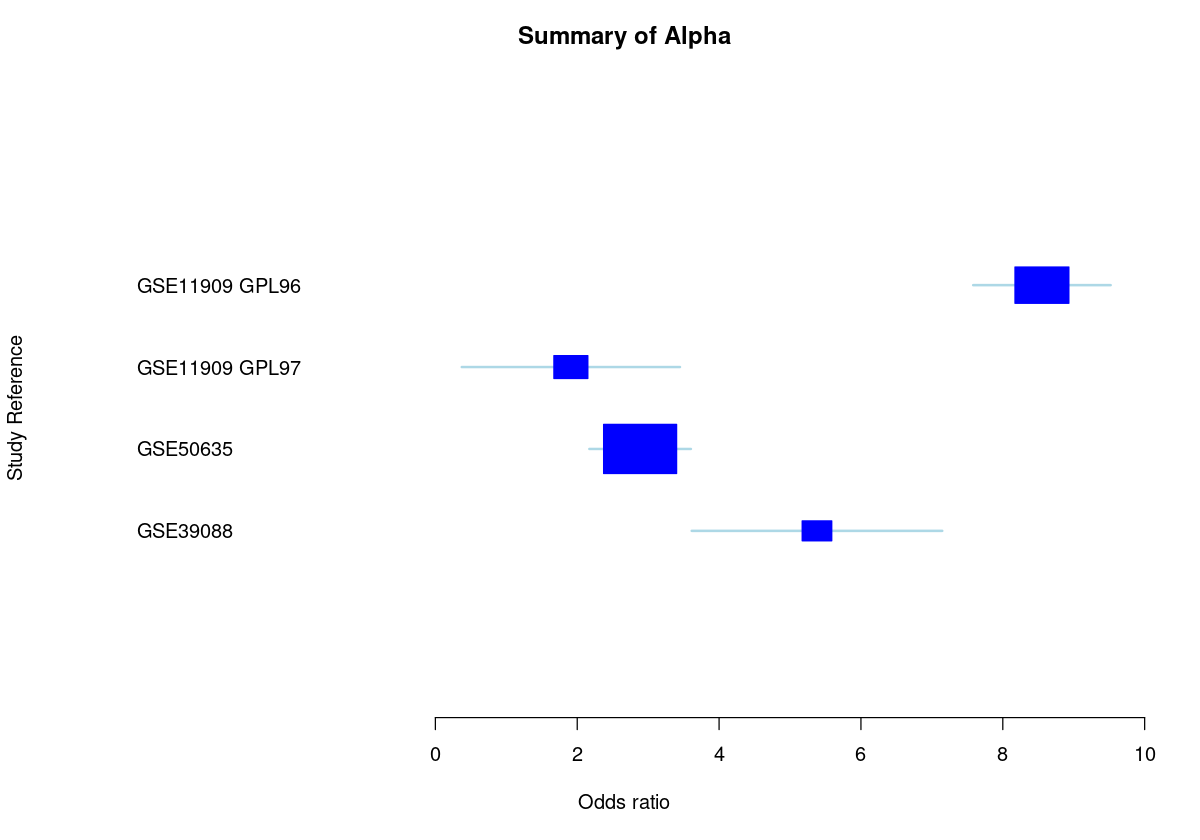

Summary ROC 
At optimal cutoff, summary sensitivity = 89.23%, summary specificity = 93.9%
At summary sensitivity = 95%, summary specificity = 0.793%                sens  spec   PPV   NPV   acc
GSE11909 GPL96 0.981 0.917 0.990 0.846 0.974
GSE11909 GPL97 0.774 0.571 0.932 0.250 0.750
GSE50635       0.818 0.812 0.900 0.684 0.816
GSE39088       0.910 0.953 0.959 0.897 0.930


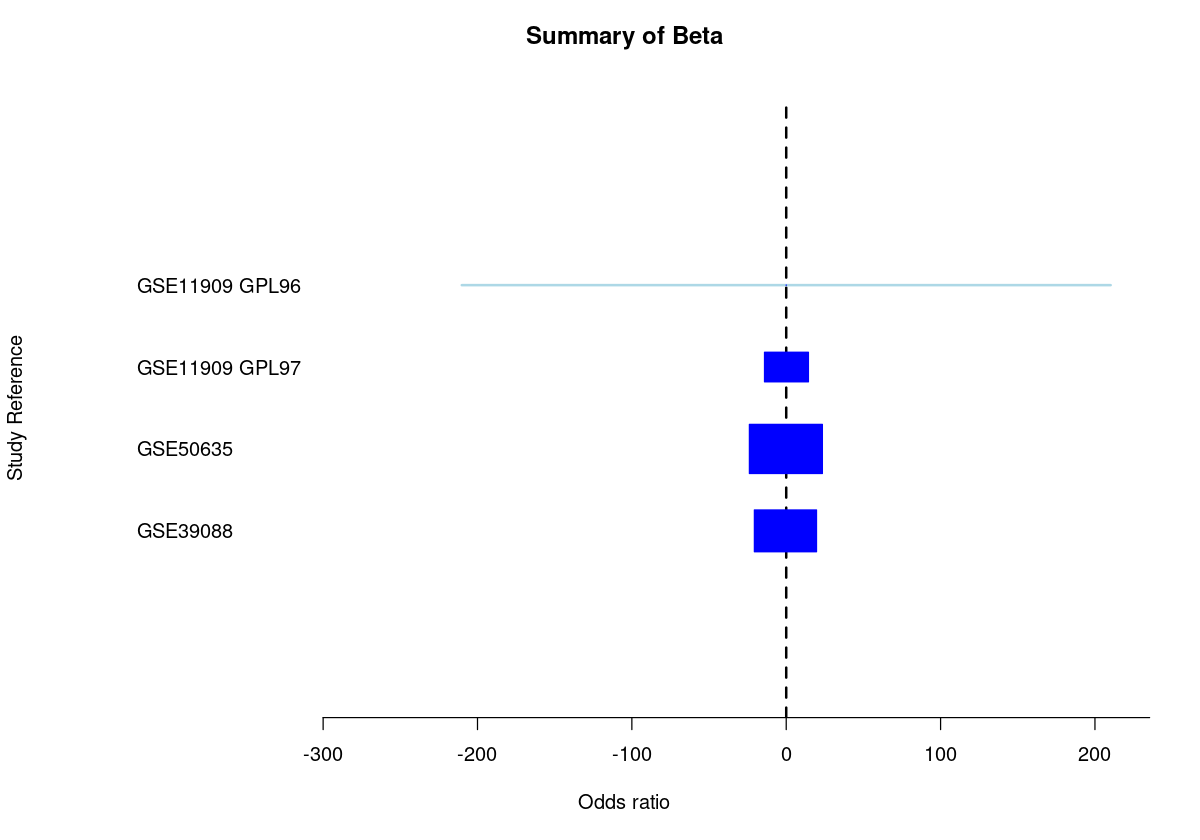

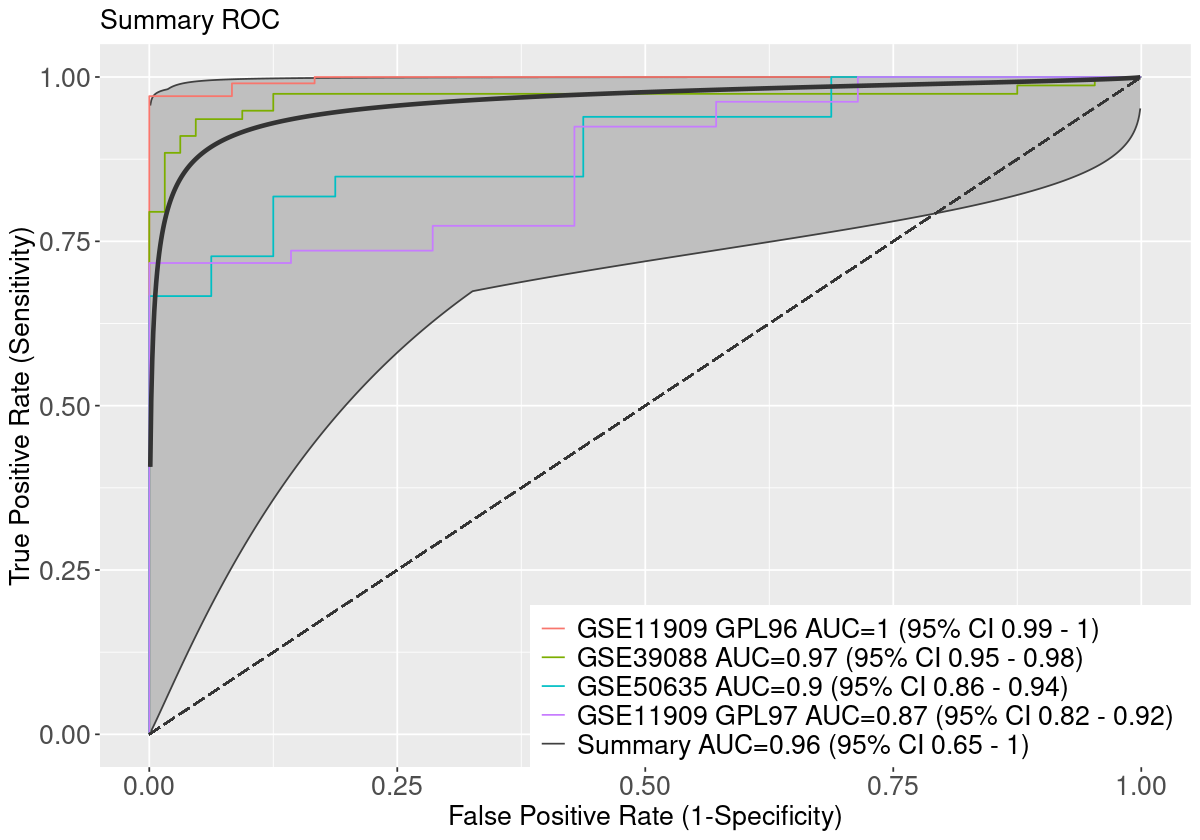

In [10]:
summaryROCPlot(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]], bootstrapReps = 100)

### 7.4 Pooled ROC

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”
Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”
Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”
Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”


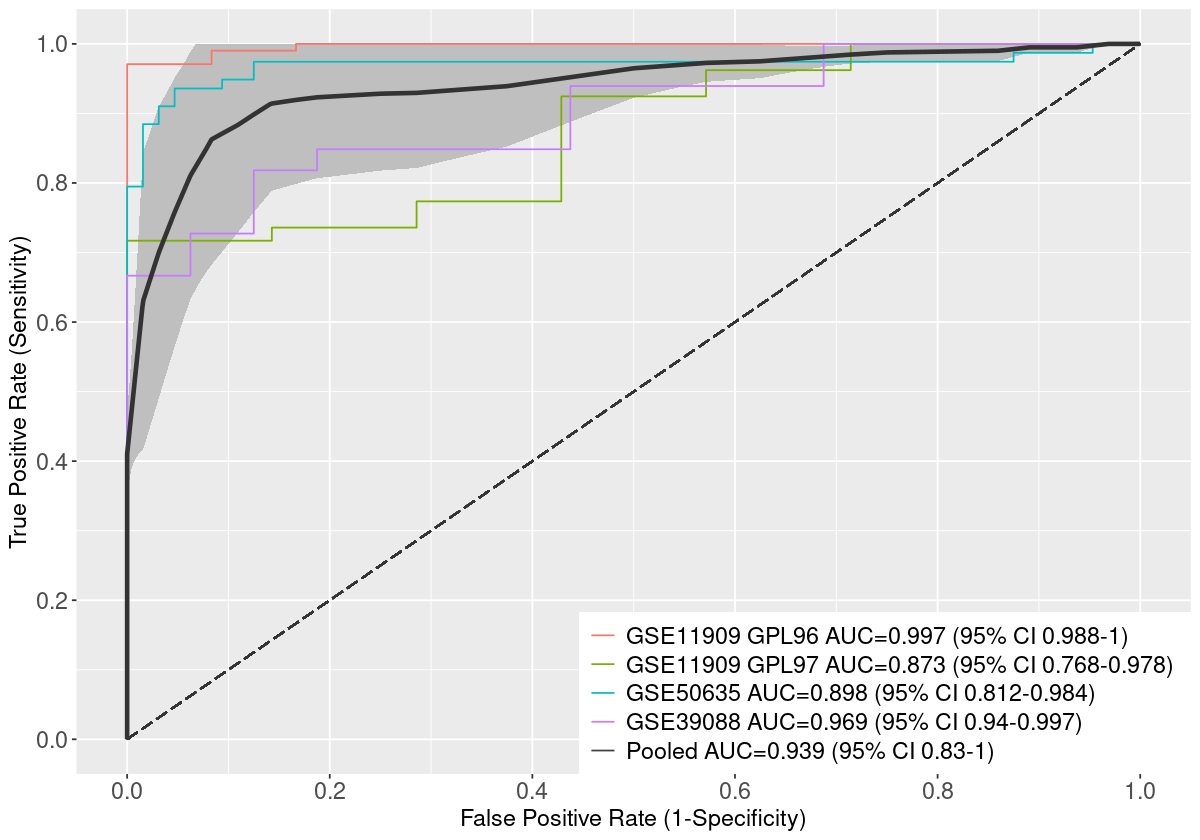

In [11]:
pooledROCPlot(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]])

### 7.5 Multiple PRC Curves

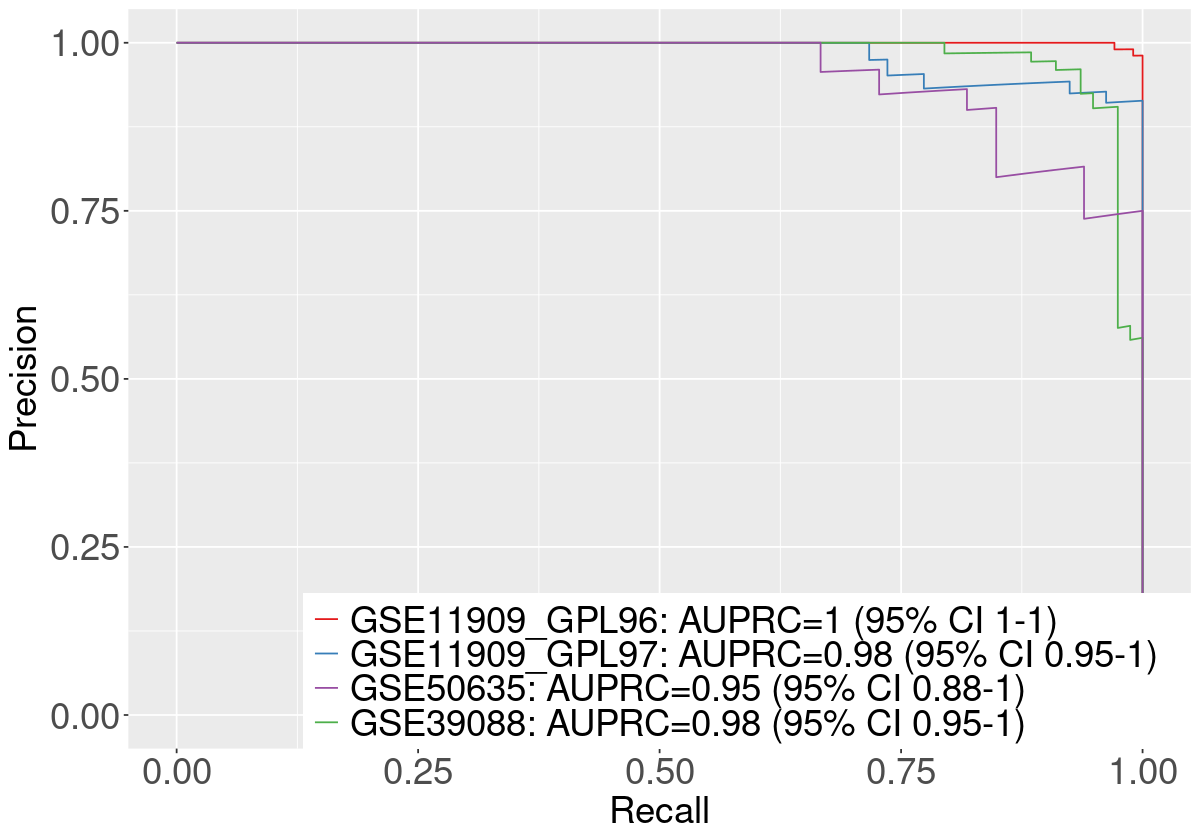

In [12]:
multiplePRCPlot(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]])

### 7.6 Violin Plot

Warning message:
“The `<scale>` argument of `guides()` cannot be `FALSE`. Use "none" instead as
of ggplot2 3.3.4.
ℹ The deprecated feature was likely used in the MetaIntegrator package.
  Please report the issue to the authors.”


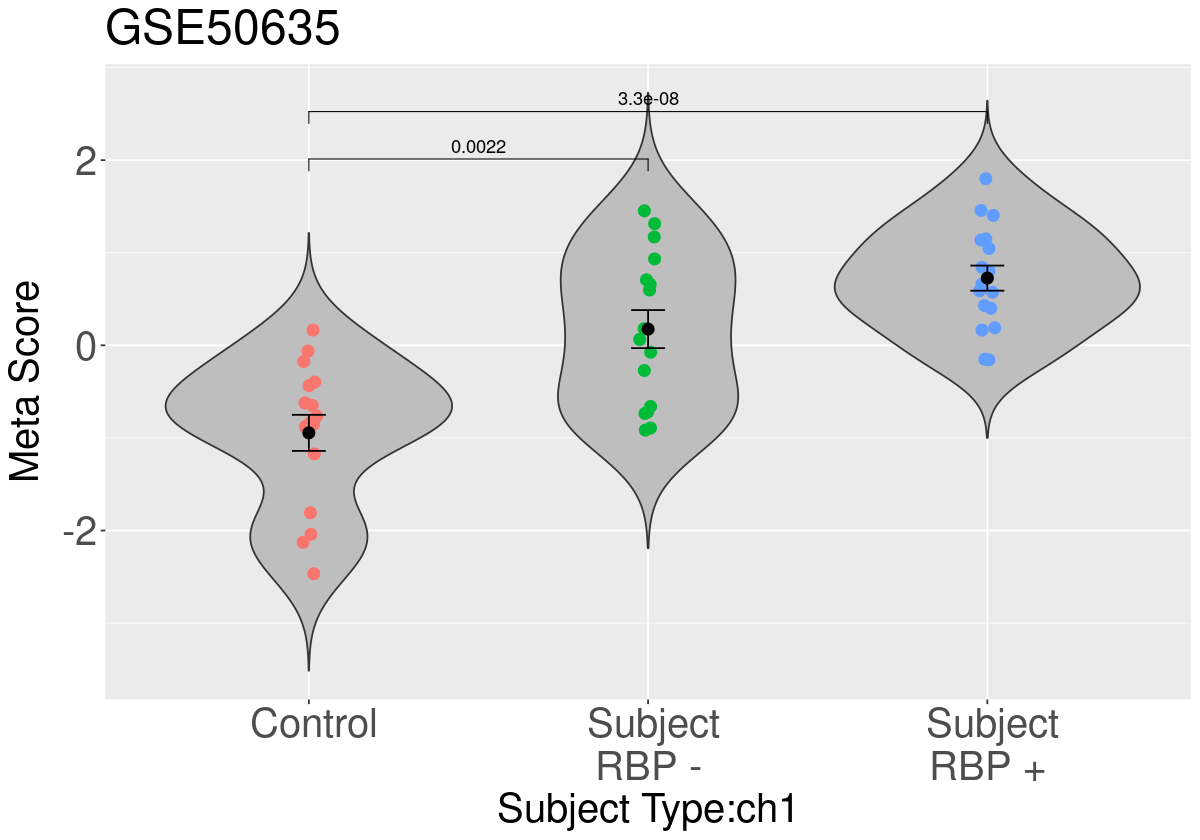

In [13]:
violinPlot(
    filterObject = sleMetaAnalysis$filterResults[[1]],
    datasetObject = sleMetaAnalysis$originalData$GSE50635,
    labelColumn = "subject type:ch1"
)

### 7.7 Regression Plot

`geom_smooth()` using formula = 'y ~ x'


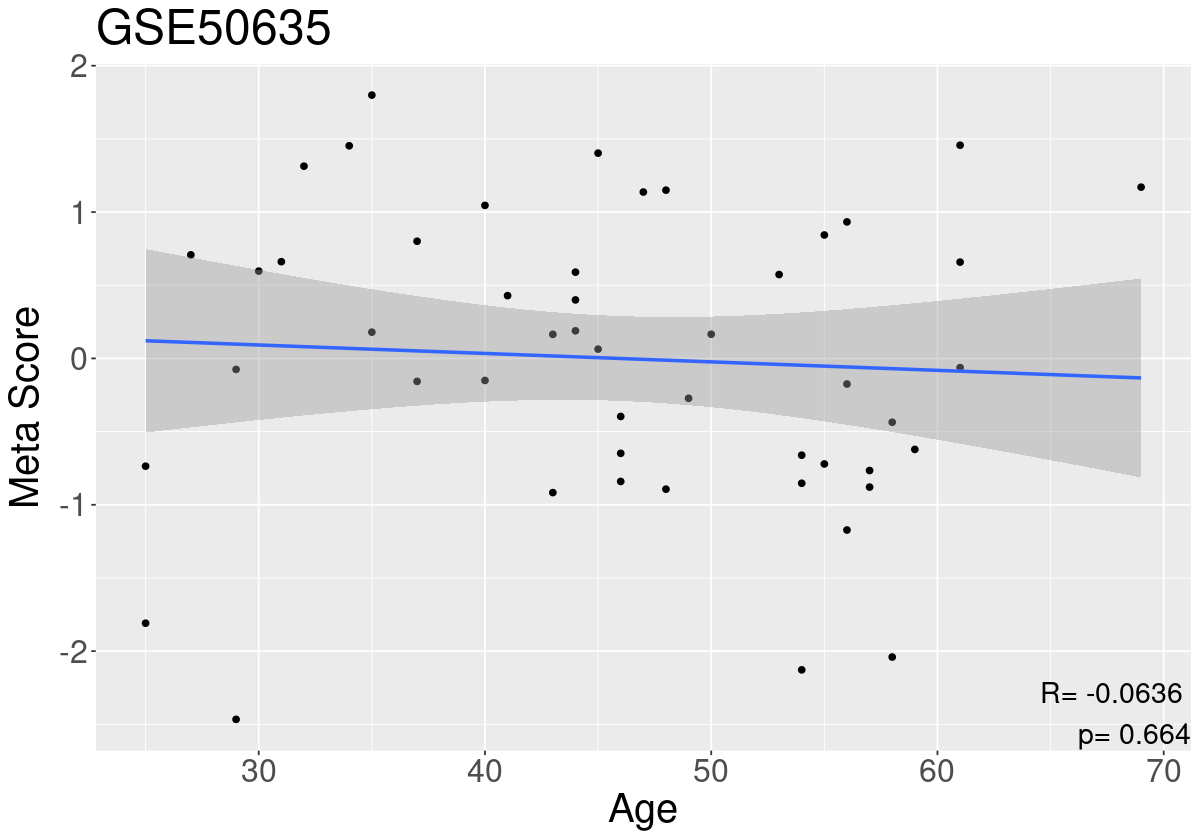

In [14]:
sleMetaAnalysis$originalData$GSE50635$pheno$`age:ch1` <- 
    as.numeric(sleMetaAnalysis$originalData$GSE50635$pheno$`age:ch1`)

regressionPlot(
    filterObject = sleMetaAnalysis$filterResults[[1]],
    datasetObject = sleMetaAnalysis$originalData$GSE50635,
    continuousVariableColumn = "age:ch1",
    formattedVariableName = "Age"
)

### 7.8 Forest Plot

[1] "character"
[1] "character"


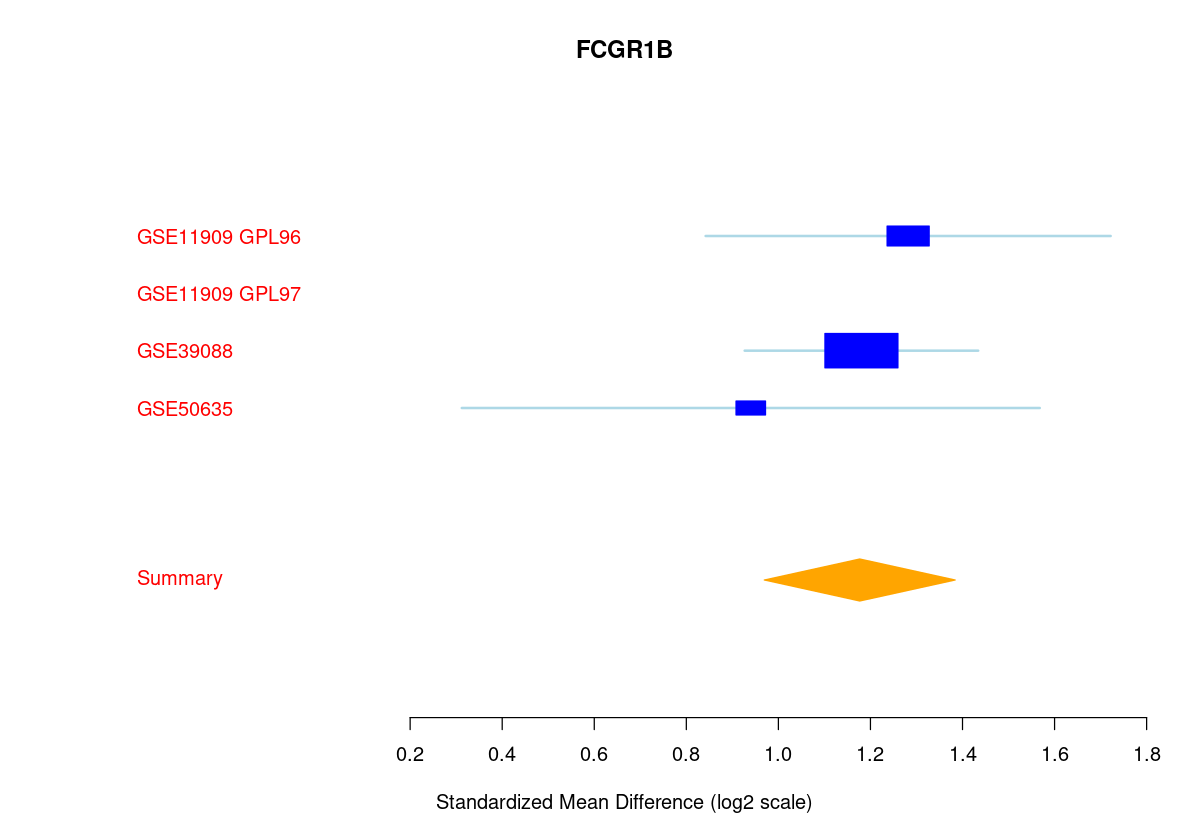

[1] "character"


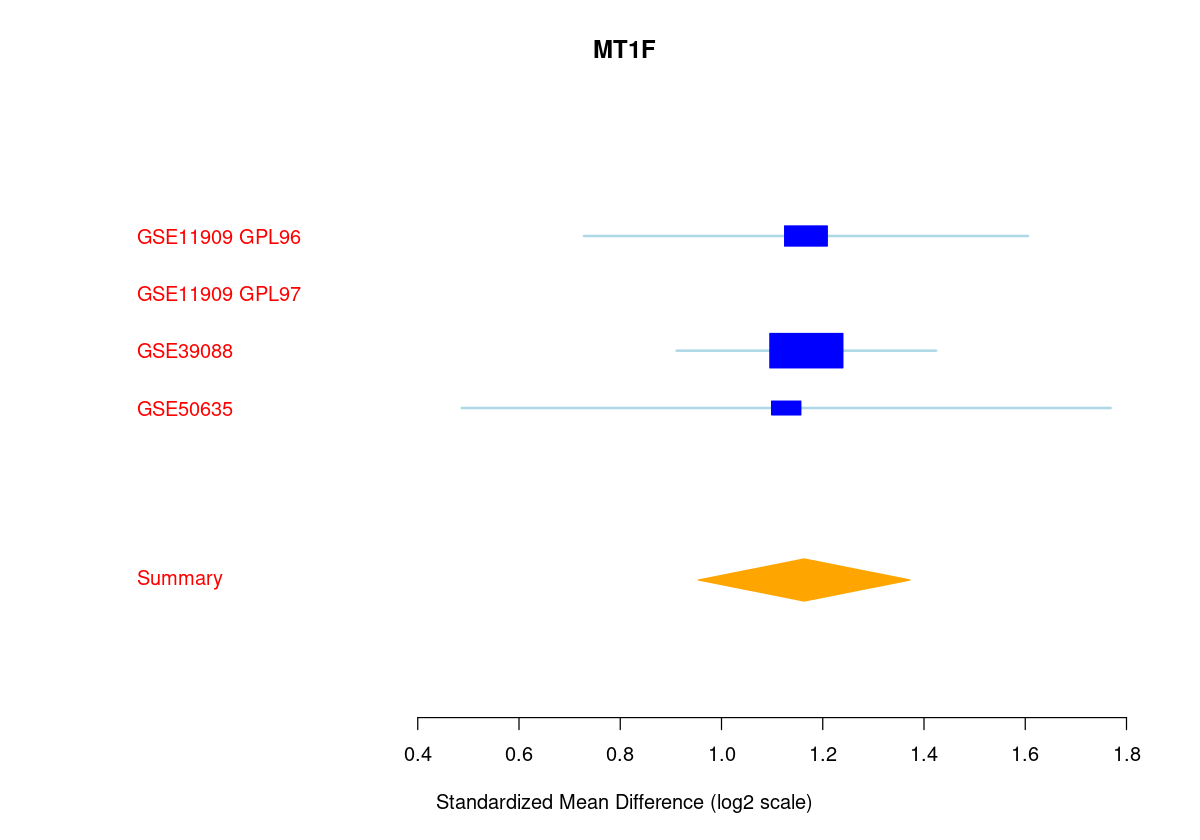

[1] "character"


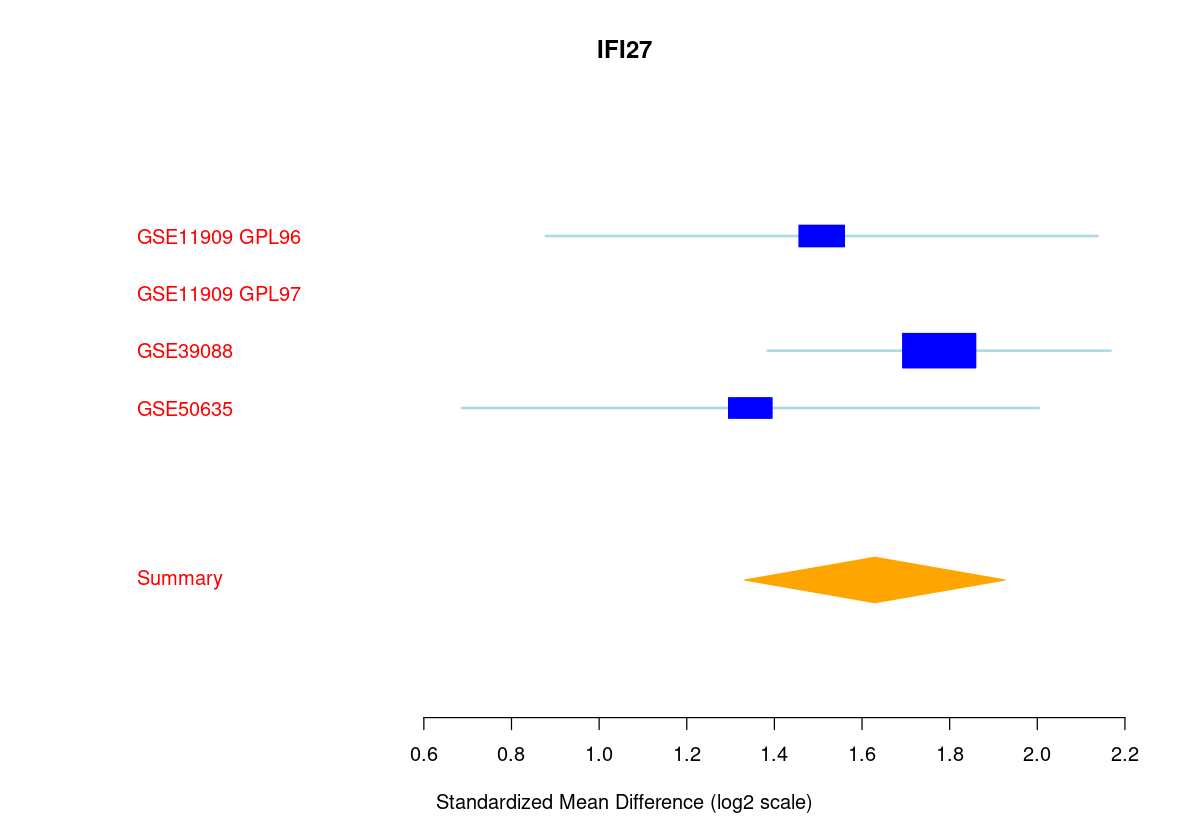

[1] "character"


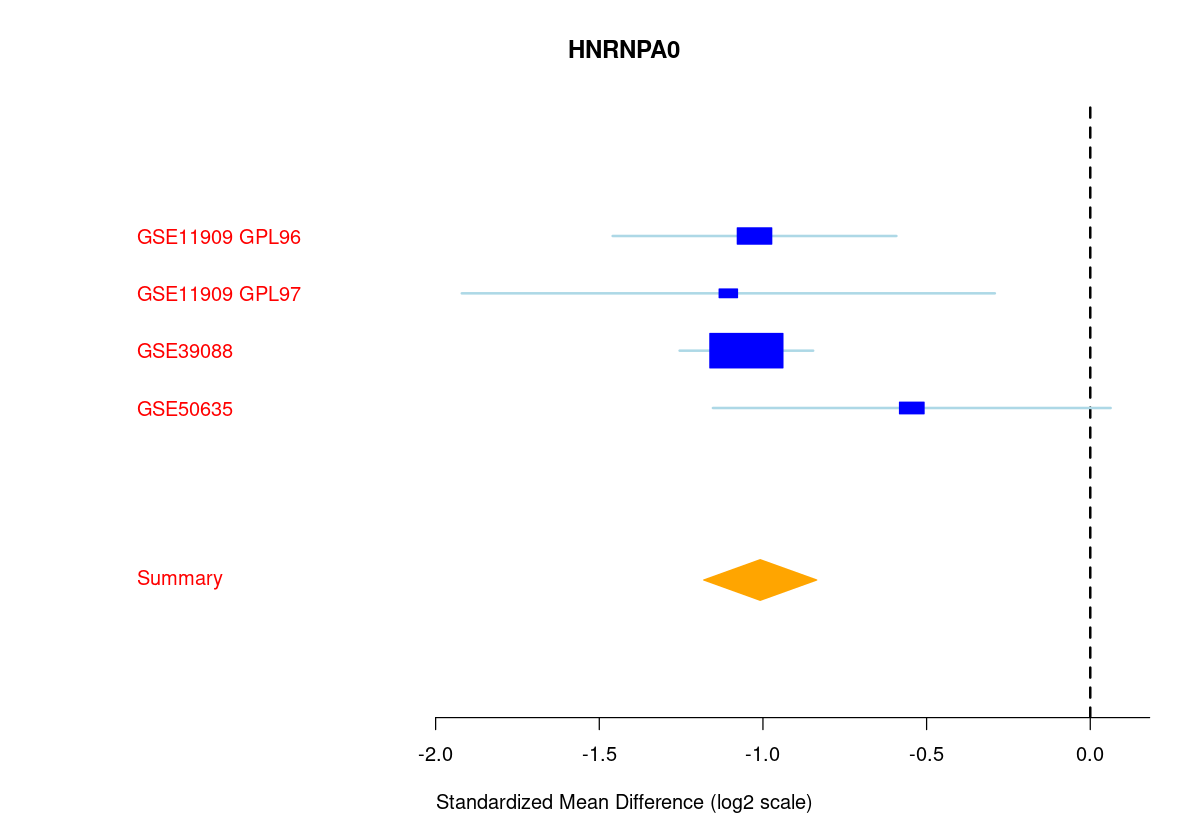

[1] "character"


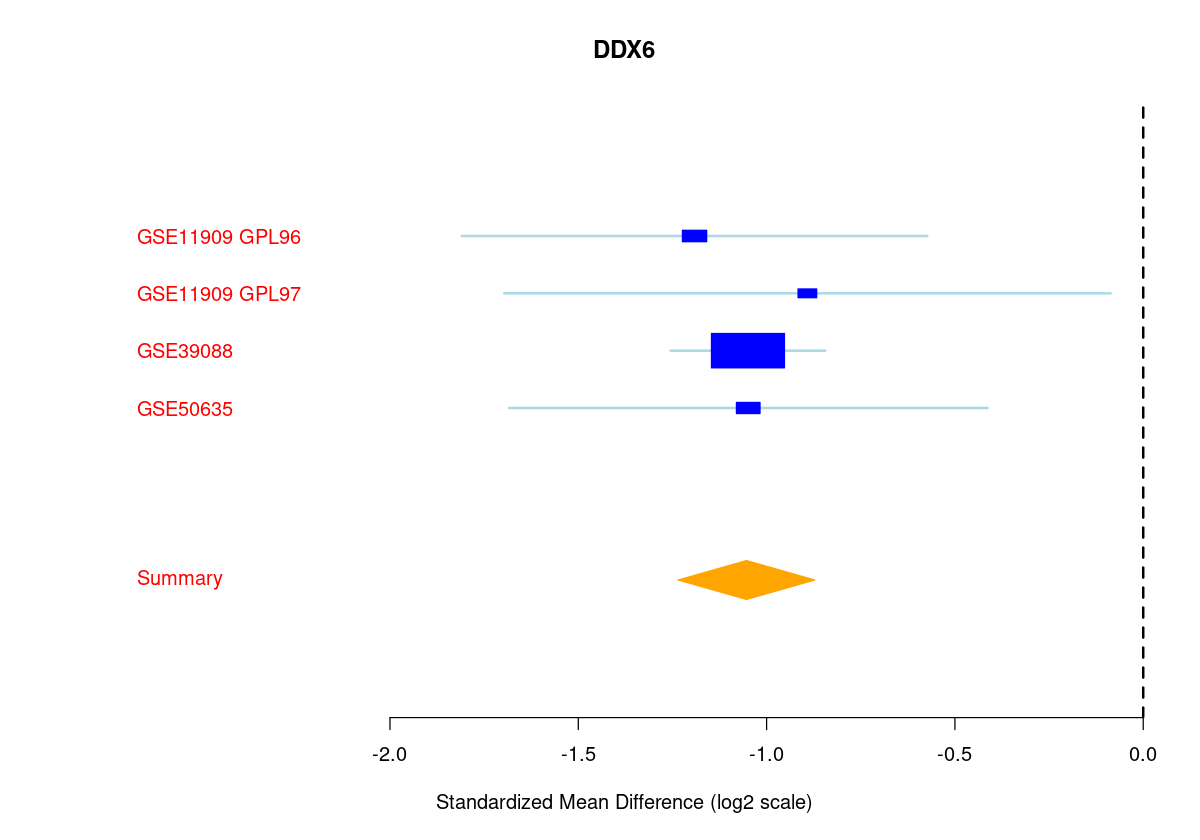

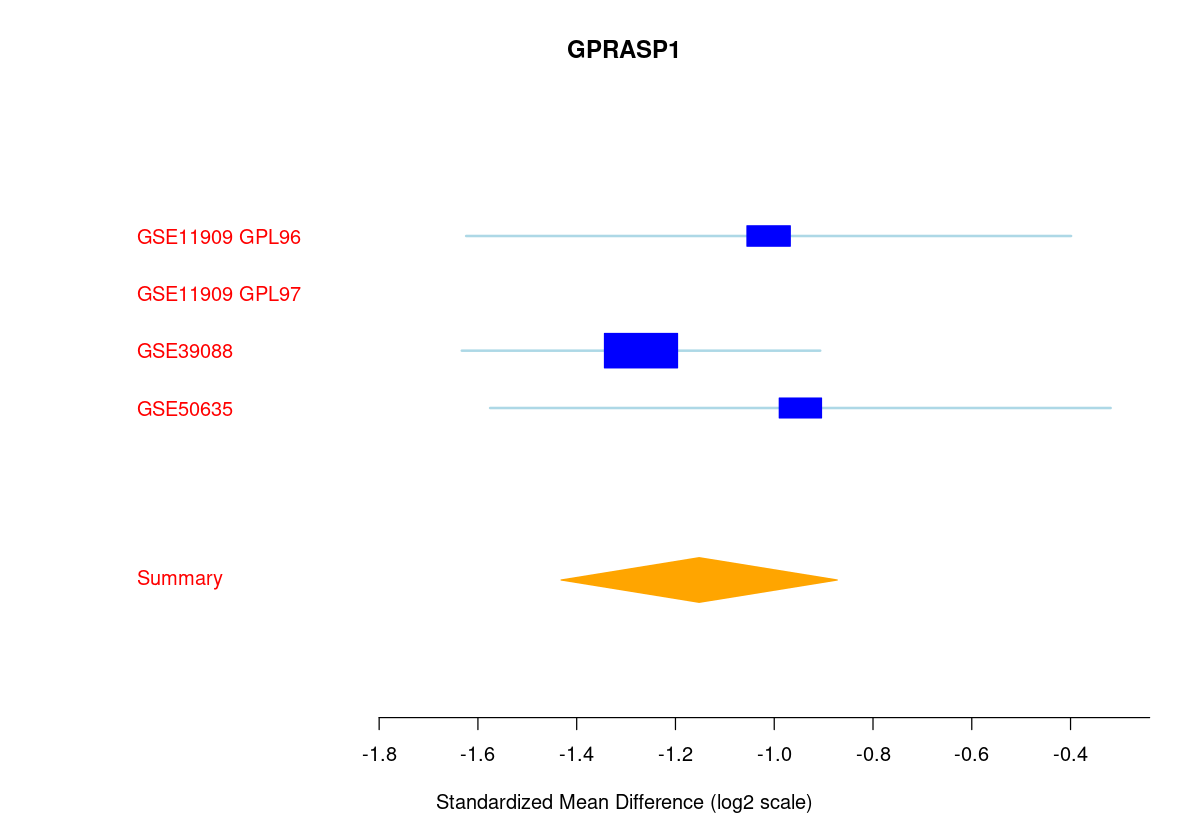

In [15]:
selected_genes <- c("FCGR1B","MT1F","IFI27","HNRNPA0","DDX6","GPRASP1")

for(gene in selected_genes){
  tryCatch(
    {
      forestPlot(geneName = gene, metaObject = sleMetaAnalysis)
    },
    error = function(e){
      warning(sprintf("Could not plot %s: %s", gene, e$message))
      # Optionally draw an empty panel to keep the layout intact
      plot.new()
      text(0.5, 0.5, paste0("Error for ", gene), cex = 1)
    }
  )
}

## 8. Save Plot Data for Cross-Platform Use

Export raw data so it can be used by either Python or R plotting modules.

In [16]:
if (SAVE_PLOT_DATA) {
    # Save effect sizes for heatmap
    sig_genes <- c(filterResults$posGeneNames, filterResults$negGeneNames)
    es_data <- sleMetaAnalysis$metaAnalysis$datasetEffectSizes[sig_genes, , drop=FALSE]
    save_plot_data(es_data, "heatmap_effect_sizes.csv", "Effect sizes for signature genes")
    
    # Save MetaScores + phenotype for violin plot
    ds <- sleMetaAnalysis$originalData$GSE50635
    scores <- calculateScore(filterResults, ds)

    # Ensure scores have sample names
    if (is.null(names(scores))) {
        names(scores) <- colnames(ds$expr)
    }
    
    # Now build the data.frame safely
    violin_df <- data.frame(
        Sample = names(scores),
        MetaScore = as.numeric(scores),
        Class = ds$class[names(scores)],
        Label = ds$pheno[names(scores), "subject type:ch1"],
        stringsAsFactors = FALSE
    )
    # violin_df <- data.frame(
    #    Sample = names(scores),
    #    MetaScore = scores,
    #    Class = ds$class[names(scores)],
    #    Label = ds$pheno[names(scores), "subject type:ch1"]
    # )
    save_plot_data(violin_df, "violin_GSE50635_subject_type.csv", "Violin plot data")
    
    # Save regression data
    reg_df <- data.frame(
        Sample = names(scores),
        MetaScore = scores,
        Age = as.numeric(ds$pheno[names(scores), "age:ch1"])
    )
    save_plot_data(reg_df, "regression_GSE50635_age.csv", "Regression plot data")
    
    # Save forest plot data for IFI44L
    if ("IFI44L" %in% rownames(sleMetaAnalysis$metaAnalysis$datasetEffectSizes)) {
        forest_df <- data.frame(
            Dataset = colnames(sleMetaAnalysis$metaAnalysis$datasetEffectSizes),
            EffectSize = as.numeric(sleMetaAnalysis$metaAnalysis$datasetEffectSizes["IFI44L",])
        )
        save_plot_data(forest_df, "forest_IFI44L.csv", "Forest plot data for IFI44L")
    }
    
    # Save pooled results for reference
    save_plot_data(sleMetaAnalysis$metaAnalysis$pooledResults, "meta_analysis_pooled_results.csv", "Full meta-analysis results")
    
    cat("All plot data exported.\n")
}

  Plot data saved: output_sle_tutorial_r_analysis/plot_data/heatmap_effect_sizes.csv
Used  13 of  13  pos genes, and  3  of  3  neg genes 
  Plot data saved: output_sle_tutorial_r_analysis/plot_data/violin_GSE50635_subject_type.csv
  Plot data saved: output_sle_tutorial_r_analysis/plot_data/regression_GSE50635_age.csv
  Plot data saved: output_sle_tutorial_r_analysis/plot_data/forest_IFI44L.csv
  Plot data saved: output_sle_tutorial_r_analysis/plot_data/meta_analysis_pooled_results.csv
All plot data exported.


## 9. Advanced Analyses (Optional)

### 9.1 Forward/Backward Search

In [17]:
# Uncomment to run (10-30 minutes)
# forwardRes <- forwardSearch(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]])
cat("Forward/backward search skipped (uncomment to run).\n")

Forward/backward search skipped (uncomment to run).


### 9.2 immunoStates Deconvolution

In [18]:
# Uncomment to run
# immunoMeta <- immunoStatesMeta(metaObject = sleMetaAnalysis)
cat("immunoStates skipped (uncomment to run).\n")

immunoStates skipped (uncomment to run).


### 9.3 LINCS Drug Correlation

In [19]:
# Uncomment to run (large download first time)
# lincsHits <- lincsCorrelate(metaObject = sleMetaAnalysis, filterObject = sleMetaAnalysis$filterResults[[1]], dataset = "CP", direction = "reverse")
cat("LINCS correlation skipped (uncomment to run).\n")

LINCS correlation skipped (uncomment to run).


### 9.4 Sex Imputation

In [20]:
imputedSex <- imputeSex(myDataset = sleMetaAnalysis$originalData$GSE11909_GPL96)
cat("Sex imputation results (first 10):\n")
print(head(imputedSex, 10))

Sex imputation results (first 10):
GSM300916 GSM300918 GSM300919 GSM300921 GSM300922 GSM300924 GSM300926 GSM300928 
 "female"  "female"  "female"  "female"  "female"  "female"  "female"  "female" 
GSM300930 GSM300931 
 "female"  "female" 


### 9.5 COCONUT Batch Correction

In [21]:
# Uncomment to run
# coconutRes <- coconutMetaIntegrator(metaObject = sleMetaAnalysis)
cat("COCONUT skipped (uncomment to run).\n")

COCONUT skipped (uncomment to run).


---

## 10. Summary

In [22]:
cat("\nANALYSIS SUMMARY\n")
cat("================\n\n")
cat("Datasets:\n")
for(name in names(sleMetaAnalysis$originalData)) {
    n <- ncol(sleMetaAnalysis$originalData[[name]]$expr)
    cat(sprintf("  %s: %d samples\n", name, n))
}
cat(sprintf("\nGenes analyzed: %d\n", nrow(sleMetaAnalysis$metaAnalysis$pooledResults)))
cat(sprintf("Signature: %d genes (%d up, %d down)\n",
    length(filterResults$posGeneNames) + length(filterResults$negGeneNames),
    length(filterResults$posGeneNames),
    length(filterResults$negGeneNames)))
cat(sprintf("\nTop 5 up: %s\n", paste(head(filterResults$posGeneNames, 5), collapse=", ")))
cat(sprintf("Top 5 down: %s\n", paste(head(filterResults$negGeneNames, 5), collapse=", ")))
cat("\nComplete.\n")


ANALYSIS SUMMARY

Datasets:
  GSE11909_GPL96: 115 samples
  GSE11909_GPL97: 60 samples
  GSE50635: 49 samples
  GSE39088: 142 samples

Genes analyzed: 25822
Signature: 16 genes (13 up, 3 down)

Top 5 up: MT1F, FCGR1B, IFITM1, IFI27, SCNM1
Top 5 down: DDX6, ABCB1, MID2

Complete.
